In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / 'core').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'figure.figsize': (7, 4)})
FIG = ROOT / 'results' / 'figures'; DATA = ROOT / 'results' / 'data'

# 05 — Keeping the additive rule when $\varepsilon>0$: manipulation and its cost

Suppose the designer ignores the complementarity and runs the original LIP(2): a report
$r$ is mapped to the Claim-5 spend $t_0(r)$ and the bundle $(Q(t_0),Q(1-t_0))$. This is what the
chatbot draft in `proposal/main.tex` analysed. We check its claims:

1. the naive rule is **not strategy-proof** for any $\varepsilon>0$;
2. the gain from misreporting is at most $\varepsilon\,Q(\tfrac12)^2/2\approx0.257\,\varepsilon$;
3. truthful play gives welfare ratio $\ge 0.828/(1+\varepsilon)$ and the worst case tends to 0;
4. **strategic play is outcome-equivalent to the $\varepsilon$-aware mechanism** (P5), so the
   right fix is simply to let the mechanism compute the $\varepsilon$-optimal bundle itself.

In [2]:
from core import eps as E, lip
a = 2.0
b = lip.b_of(a)
Q = lambda t: lip.Q(t, a)
t0 = lambda r: lip.spend_additive(r, a)                      # naive spend from a report

def dictator_utility_from_report(x, r, e):
    t = t0(r); return E.utility(x, Q(t), Q(1 - t), e)

# 1. a profitable deviation (draft's Step-1 example: true x = 0.8, eps = 1)
x, e = 0.8, 1.0
rs = np.linspace(0, 1, 2001)
u = dictator_utility_from_report(x, rs, e)
print(f"true type {x}, eps={e}: truthful utility {dictator_utility_from_report(x, x, e):.4f}, best report {rs[np.argmax(u)]:.3f} gives {u.max():.4f}")

true type 0.8, eps=1.0: truthful utility 1.0596, best report 0.588 gives 1.2572


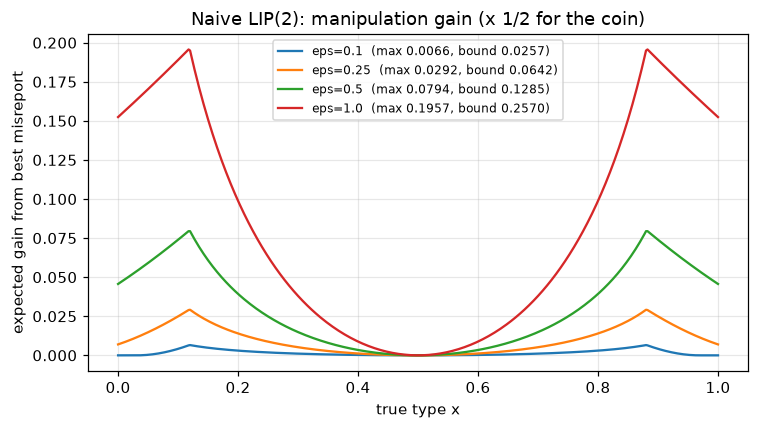

In [3]:
# 2. maximal gain from misreporting, as a function of the true type, for several eps
xs = np.linspace(0, 1, 401)
fig, ax = plt.subplots(figsize=(7, 4))
for e in (0.1, 0.25, 0.5, 1.0):
    gain = np.array([ (dictator_utility_from_report(x, rs, e).max() - dictator_utility_from_report(x, x, e)) for x in xs ])
    ax.plot(xs, 0.5 * gain, label=f"eps={e}  (max {0.5*gain.max():.4f}, bound {e*Q(0.5)**2/2:.4f})")
ax.set(xlabel="true type x", ylabel="expected gain from best misreport", title="Naive LIP(2): manipulation gain (x 1/2 for the coin)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "05_manipulation_gain.png"); plt.show()

The draft's bound $\varepsilon C/2$ with $C=Q(\tfrac12)^2\approx0.514$ holds but is loose by a
factor of 2–3: the gain is largest for *extreme* types (who are pushed off their all-in corner
to buy some of the complementary item) and vanishes for the balanced type $x=\tfrac12$ whose
additive choice is already the $\varepsilon$-optimal one.

## 3. Welfare under truthful play vs strategic play

In [4]:
g = np.linspace(0, 1, 401); X, Y = np.meshgrid(g, g, indexing="ij"); m = X >= Y; X, Y = X[m], Y[m]
def truthful_naive_welfare(X, Y, e):
    q1x, q2x = lip.bundle_additive(X, a); q1y, q2y = lip.bundle_additive(Y, a)
    return 0.5 * (E.utility(X, q1x, q2x, e) + E.utility(Y, 1 - q1x, 1 - q2x, e) + E.utility(Y, q1y, q2y, e) + E.utility(X, 1 - q1y, 1 - q2y, e))
rows = []
for e in (0, 0.01, 0.1, 0.5, 1.0, 2.0):
    OPT = E.first_best(X, Y, e)
    rt = (truthful_naive_welfare(X, Y, e) / OPT); rs_ = E.ratio_lip(X, Y, a, e)
    rows.append({"eps": e, "truthful naive LIP(2) (min ratio)": rt.min(), "strategic = eps-aware LIP(2)": rs_.min(),
                 "equal split": (1 + e / 2) / (1 + max(e, 1)), "draft truthful": {0: .82815, .01: .83017, .1: .84835, .5: .66667, 1: .5, 2: .33333}[e],
                 "draft strategic": {0: .82815, .01: .83082, .1: .84028, .5: .81002, 1: .76515, 2: .71528}[e], "bound 0.828/(1+eps)": 0.828 / (1 + e)})
pd.DataFrame(rows).round(5)

,eps,truthful naive LIP(2) (min ratio),strategic = eps-aware LIP(2),equal split,draft truthful,draft strategic,bound 0.828/(1+eps)
0,0.00,0.82815,0.82815,0.50000,0.82815,0.82815,0.82800
1,0.01,0.83017,0.83082,0.50250,0.83017,0.83082,0.81980
2,0.10,0.84835,0.84028,0.52500,0.84835,0.84028,0.75273
3,0.50,0.66667,0.81002,0.62500,0.66667,0.81002,0.55200
4,1.00,0.50000,0.76515,0.75000,0.50000,0.76515,0.41400
5,2.00,0.33333,0.71528,0.66667,0.33333,0.71528,0.27600


Both columns of the draft's table are reproduced. Truthful play under the naive rule collapses
like $1/(1+\varepsilon)$ (at $x=y=0$ both agents want item 2 only, the naive dictator never buys
item 1, welfare stays 1 while the first best is $1+\varepsilon$); strategic play is better
*because* the agents do the $\varepsilon$-optimisation the mechanism refused to do. Since the
mechanism can do that optimisation itself without losing strategy-proofness (P2), there is no
reason to run the naive rule.

## 4. Sanity check of P5: strategic outcome = $\varepsilon$-aware outcome

In [5]:
xs = np.linspace(0, 1, 201); e = 0.7
best_r = np.array([rs[np.argmax(dictator_utility_from_report(x, rs, e))] for x in xs])
t_strat = t0(best_r); t_aware = E.spend_eps(xs, a, e)
print("max |t(best report) - t*(x)| over 201 types:", np.max(np.abs(t_strat - t_aware)).round(4), "(report grid step 5e-4)")

max |t(best report) - t*(x)| over 201 types: 0.0003 (report grid step 5e-4)
